# GROUP 10 - Swahili Sentiment Analysis (CDS 3301 Machine Learning)
**Meru University of Science and Technology** | Task: text classification (positive / negative / neutral)

**How to run:** *Kernel -> Restart & Run All* (Colab: *Runtime -> Run all*). Everything is seeded (`SEED = 42`), so results are reproducible. The very last cell is an interactive demo; it is switched off by default (`INTERACTIVE = False`) so *Run All* never waits for typing - set it to `True` for the live presentation.

**Data (README):** AfriSenti Swahili subset (SemEval-2023 Task 12). The notebook tries, in order: (1) the AfriSenti GitHub repository `SubtaskA/train/sw_train.tsv` + `SubtaskA/dev/sw_dev.tsv`, (2) Hugging Face `shmuhammad/AfriSenti-twitter-sentiment` (config `swa`), (3) a local `swahili_sentiment.csv` (columns `text`, `label`), (4) a Colab upload, (5) a tiny demo set (only so the code never crashes - never use it for real results).
Sources: https://github.com/afrisenti-semeval/afrisent-semeval-2023 | https://huggingface.co/datasets/shmuhammad/AfriSenti-twitter-sentiment

**Workflow in this notebook:** Tasks 1-5 build and evaluate the **Stage-1** model (best of five classifiers). **Task 5b (Stage 2)** then fixes the weakness found in Stage 1 - the model almost never detects *negative* tweets - using character n-grams and cross-validated decision-threshold tuning. The test set is used only for the final reporting of each stage, never for any choice.

**AI-use declaration:** this notebook was drafted with help from Claude (Anthropic).

## Step 0 - Install and import

In [1]:
import importlib, subprocess, sys
for pkg, mod in [("datasets", "datasets"), ("requests", "requests"), ("joblib", "joblib"), ("scikit-learn", "sklearn"), ("matplotlib", "matplotlib"), ("pandas", "pandas")]:
    try:
        importlib.import_module(mod)
    except ImportError:
        try:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
        except Exception as e:
            print(f"[warn] could not install {pkg}; continuing (fallback data sources will be used)")
print("Packages ready")

Packages ready


In [2]:
import os, re, io, warnings, random
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, roc_auc_score)

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)
LABELS = ["negative", "neutral", "positive"]
print("Imports OK")

Imports OK


## Task 1 - Problem framing and data understanding
**Problem:** classify Swahili social-media text as positive, negative or neutral.
**Beneficiaries:** brands, NGOs, government and researchers monitoring Kenyan public opinion; low-resource NLP community.
**Target:** `label` (3 classes). **Success metric:** *macro F1* (treats all classes equally, robust to imbalance), with accuracy, precision, recall and ROC-AUC reported too. We also track **recall on the negative class** because missing complaints is the costliest error for the intended users.
**Dataset:** AfriSenti (Muhammad et al., 2023) Swahili tweets, annotated by native speakers. Licence: the Hugging Face card for the dataset we cite states **CC BY 4.0** (a mirror of the same data lists CC BY-NC-SA 4.0; our use is non-commercial and academic, so it complies with both). Limitations: small size, Twitter-only, annotation noise, code-switching with English/Sheng.

## Task 2 - Data loading, preparation and exploratory analysis
### 2a. Load data (tries several sources automatically)

In [3]:
def _std(df):
    df = df.copy()
    tcol = next((c for c in ["tweet", "text", "Tweet", "Text"] if c in df.columns), None)
    if tcol is None or "label" not in df.columns:
        raise ValueError(f"Need text and label columns, got {list(df.columns)}")
    df = df.rename(columns={tcol: "text"})[["text", "label"]]
    return df

def load_hf():
    from datasets import load_dataset
    ds = load_dataset("shmuhammad/AfriSenti-twitter-sentiment", "swa")   # newer `datasets` versions no longer run dataset scripts
    frames = []
    for split in ds.keys():
        d = ds[split]
        df = d.to_pandas()
        feat = d.features.get("label")
        if hasattr(feat, "names"):
            names = feat.names
            df["label"] = df["label"].map(lambda i: names[int(i)] if str(i).lstrip("-").isdigit() and int(i) >= 0 else None)
        frames.append(_std(df))
    return pd.concat(frames, ignore_index=True)

def load_github():
    import requests
    base = "https://raw.githubusercontent.com/afrisenti-semeval/afrisent-semeval-2023/main/SubtaskA/"
    frames = []
    for part in ["train/sw_train.tsv", "dev/sw_dev.tsv"]:
        r = requests.get(base + part, timeout=30)
        r.raise_for_status()
        frames.append(_std(pd.read_csv(io.StringIO(r.text), sep="\t")))
    return pd.concat(frames, ignore_index=True)

def load_local():
    return _std(pd.read_csv("swahili_sentiment.csv"))

def load_demo():
    pos = ["Huduma ni nzuri sana, nimefurahi!", "Napenda sana wimbo huu, ni mzuri", "Asante sana kwa msaada wako, you are the best",
           "Habari njema leo, tumeshinda!", "Kazi nzuri sana, hongera wote", "Nimefurahi sana na matokeo haya",
           "Chakula kilikuwa kitamu sana", "Mpango huu ni mzuri kwa wananchi", "Leo ni siku nzuri, nina furaha tele",
           "Uongozi bora, tunaipenda serikali hii"]
    neg = ["Huduma ni mbaya sana, nimechukia", "Sipendi kabisa tabia hii, ni mbaya", "Barabara ni mbovu, this is terrible",
           "Bei zimepanda, maisha ni magumu sana", "Nimekasirika sana na uongozi huu", "Huu ni wizi mtupu, aibu kubwa",
           "Wameshindwa kazi yao kabisa", "Hospitali haina dawa, hali ni mbaya", "Tumechoka na ahadi za uongo",
           "Mchezo ulikuwa mbaya, timu ilifungwa vibaya"]
    neu = ["Mkutano utafanyika kesho saa tatu asubuhi", "Basi linaondoka saa mbili usiku", "Ofisi ipo karibu na stendi kuu",
           "Waziri atatoa taarifa leo mchana", "Mvua inatarajiwa wiki ijayo", "Soko hufunguliwa kila siku asubuhi",
           "Tarehe ya mtihani imetangazwa", "Shule zitafunguliwa Jumatatu", "Kuna mkutano wa wazazi shuleni", "Treni inafika Nairobi saa nne"]
    rows = [(t, "positive") for t in pos] + [(t, "negative") for t in neg] + [(t, "neutral") for t in neu]
    return pd.DataFrame(rows, columns=["text", "label"])

df_raw, SOURCE = None, None
for name, fn in [("GitHub AfriSenti", load_github), ("HuggingFace AfriSenti", load_hf),
                 ("local swahili_sentiment.csv", load_local)]:
    try:
        df_raw = fn(); SOURCE = name
        break
    except Exception as e:
        print(f"[skip] {name} failed: {type(e).__name__}: {str(e)[:120]}")
if df_raw is None:
    try:   # Google Colab: let the user upload a CSV/TSV with text + label columns
        from google.colab import files
        print("\nUpload a CSV/TSV file with columns 'text' (or 'tweet') and 'label'. Cancel to use demo data.")
        up = files.upload()
        if up:
            fname = list(up.keys())[0]
            df_raw = _std(pd.read_csv(io.BytesIO(up[fname]), sep=None, engine="python"))
            SOURCE = "uploaded file: " + fname
    except Exception as e:
        print("[skip] upload:", type(e).__name__)
if df_raw is None:
    df_raw = load_demo(); SOURCE = "TINY DEMO DATA (no real dataset reachable!)"
    print("\n!!! WARNING: using tiny demo data. Connect to the internet (or add swahili_sentiment.csv) for real results. !!!")

print("\nSource:", SOURCE, "| rows:", len(df_raw))
df_raw.head()


Source: GitHub AfriSenti | rows: 2263


,text,label
0,Kwani tanesco wanakataga umeme makusudinadhani...,negative
1,cjawahi kuona content yoyote zaidi ya kuwa ana...,negative
2,Bomu lililokuwa limetegwa ndani ya gari likiwa...,negative
3,Kuna video inasambaa mitandaoni jamaa amemfuma...,negative
4,Viwavijeshi wanapita katika hatua kuu 6 za uku...,negative


### Data preparation: missing values, duplicates, cleaning

In [4]:
print("Missing values before:\n", df_raw.isna().sum(), "\n")
df = df_raw.copy()
df["label"] = df["label"].astype(str).str.strip().str.lower()
df = df[df["label"].isin(LABELS)]
df = df.dropna(subset=["text"])

def clean_text(t):
    t = str(t).lower()
    t = re.sub(r"http\S+|www\.\S+", " ", t)      # urls
    t = re.sub(r"@\w+", " ", t)                    # mentions (removes personal handles -> privacy)
    t = t.replace("#", " ")
    t = re.sub(r"[^\w\s]", " ", t)                # punctuation / emojis
    t = re.sub(r"\d+", " ", t)
    return re.sub(r"\s+", " ", t).strip()

df["clean"] = df["text"].apply(clean_text)
df = df[df["clean"].str.len() > 0]

n0 = len(df)
df = df.drop_duplicates(subset="clean", keep="first")           # duplicates
print(f"Removed {n0-len(df)} duplicates. Rows now: {len(df)}")

df["n_words"] = df["clean"].str.split().str.len()
df["n_chars"] = df["clean"].str.len()
# outliers: cap extremely long texts (IQR rule) instead of dropping
q1, q3 = df["n_words"].quantile([.25, .75]); upper = q3 + 3*(q3-q1)
print("Outlier threshold (words):", upper, "| texts above it:", int((df["n_words"] > upper).sum()))
df = df[df["n_words"] <= upper].reset_index(drop=True)

# Code-switching feature: share of common English words in the text
ENGLISH = set('''the be to of and a in that have i it for not on with he as you do at this but his by from they we say her she or an will my one all would there their what so up out if about who get which go me when make can like time no just him know take people into year your good some could them see other than then now look only come its over think also back after use two how our work first well way even new want because any these give day most us is are was were am has had did does been being very much too really love hate great bad nice thanks thank please government president money life happy sad best worst'''.split())
def en_ratio(t):
    w = t.split()
    return sum(x in ENGLISH for x in w) / len(w) if w else 0.0
df["en_ratio"] = df["clean"].apply(en_ratio)
df["code_switched"] = (df["en_ratio"] >= 0.2).astype(int)
print("Share of code-switched texts:", round(df["code_switched"].mean(), 3))
print("\nClass counts:\n", df["label"].value_counts())
df[["text", "clean", "label"]].head()

Missing values before:
 text     0
label    0
dtype: int64 

Removed 19 duplicates. Rows now: 2244
Outlier threshold (words): 43.0 | texts above it: 3
Share of code-switched texts: 0.012

Class counts:
 label
neutral     1334
positive     668
negative     239
Name: count, dtype: int64


,text,clean,label
0,Kwani tanesco wanakataga umeme makusudinadhani...,kwani tanesco wanakataga umeme makusudinadhani...,negative
1,cjawahi kuona content yoyote zaidi ya kuwa ana...,cjawahi kuona content yoyote zaidi ya kuwa ana...,negative
2,Bomu lililokuwa limetegwa ndani ya gari likiwa...,bomu lililokuwa limetegwa ndani ya gari likiwa...,negative
3,Kuna video inasambaa mitandaoni jamaa amemfuma...,kuna video inasambaa mitandaoni jamaa amemfuma...,negative
4,Viwavijeshi wanapita katika hatua kuu 6 za uku...,viwavijeshi wanapita katika hatua kuu za ukuaj...,negative


## Task 2 - Exploratory data analysis (6 visualisations)

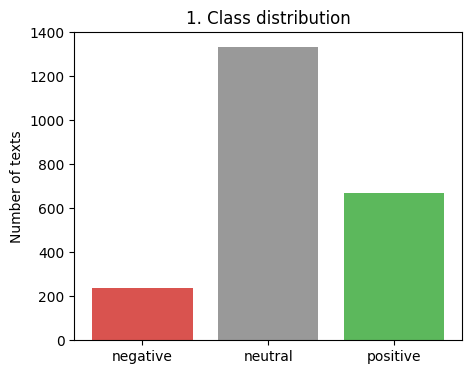

Interpretation: check if classes are balanced; imbalance is why we use macro-F1, not only accuracy.


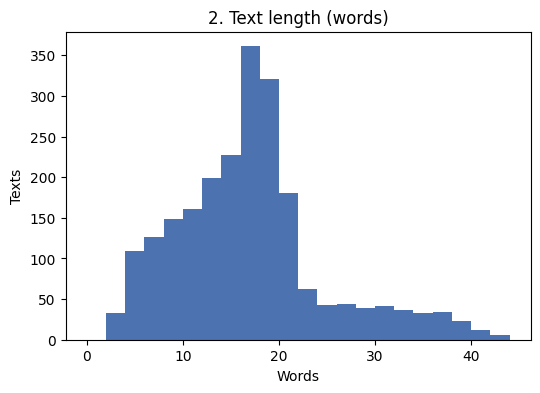

Interpretation: tweets are short, so features are sparse and every word matters.


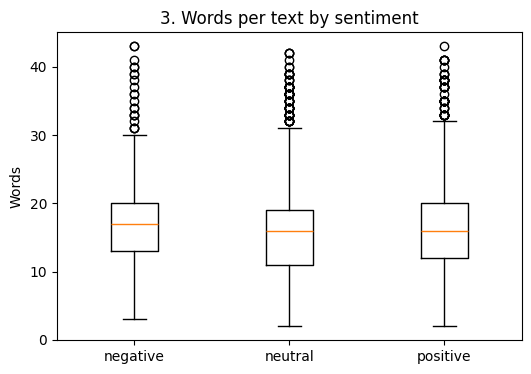

Interpretation: if medians are similar, length alone does not separate sentiment.


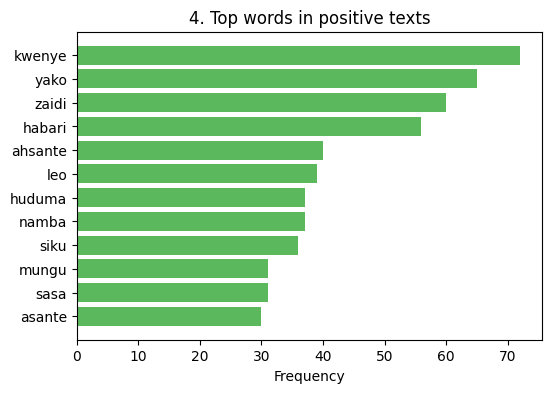

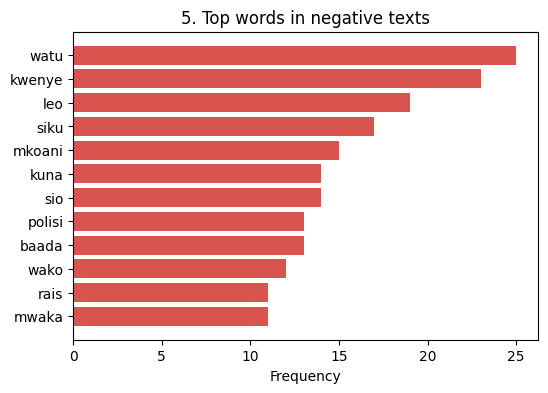

Interpretation: words that dominate each class hint at what the model will learn.


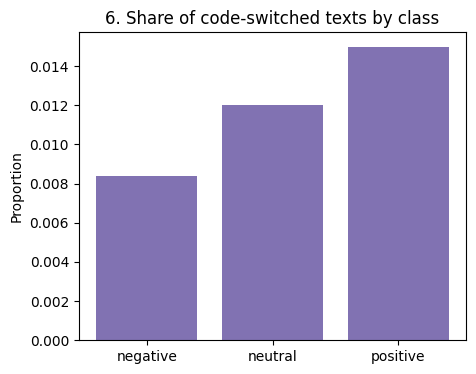

Interpretation: shows whether English mixing is linked to particular sentiments.


In [5]:
# 1. Class distribution
counts = df["label"].value_counts().reindex(LABELS).fillna(0)
plt.figure(figsize=(5,4)); plt.bar(counts.index, counts.values, color=["#d9534f","#999999","#5cb85c"])
plt.title("1. Class distribution"); plt.ylabel("Number of texts"); plt.show()
print("Interpretation: check if classes are balanced; imbalance is why we use macro-F1, not only accuracy.")

# 2. Length histogram
plt.figure(figsize=(6,4)); plt.hist(df["n_words"], bins=range(0, int(df["n_words"].max())+2, 2), color="#4c72b0")
plt.title("2. Text length (words)"); plt.xlabel("Words"); plt.ylabel("Texts"); plt.show()
print("Interpretation: tweets are short, so features are sparse and every word matters.")

# 3. Words per class (boxplot)
plt.figure(figsize=(6,4)); plt.boxplot([df.loc[df.label==l, "n_words"] for l in LABELS]); plt.xticks([1,2,3], LABELS)
plt.title("3. Words per text by sentiment"); plt.ylabel("Words"); plt.show()
print("Interpretation: if medians are similar, length alone does not separate sentiment.")

# 4 & 5. Top words for positive / negative
STOP_SW = set("na ya wa kwa ni la za katika kuwa hii huu hiyo yake wake kama pia sana hata lakini au ili cha vya hiyo hizo ile yao yetu wetu mimi wewe sisi ndio si hu ku a i u".split())
def top_words(label, k=12):
    c = Counter(w for t in df.loc[df.label==label, "clean"] for w in t.split() if w not in STOP_SW and w not in ENGLISH and len(w) > 2)
    return c.most_common(k)
for i, lab in enumerate(["positive", "negative"], start=4):
    tw = top_words(lab)
    if tw:
        w, c = zip(*tw)
        plt.figure(figsize=(6,4)); plt.barh(w[::-1], c[::-1], color="#5cb85c" if lab=="positive" else "#d9534f")
        plt.title(f"{i}. Top words in {lab} texts"); plt.xlabel("Frequency"); plt.show()
print("Interpretation: words that dominate each class hint at what the model will learn.")

# 6. Code-switching by class
cs = df.groupby("label")["code_switched"].mean().reindex(LABELS)
plt.figure(figsize=(5,4)); plt.bar(cs.index, cs.values, color="#8172b2")
plt.title("6. Share of code-switched texts by class"); plt.ylabel("Proportion"); plt.show()
print("Interpretation: shows whether English mixing is linked to particular sentiments.")

## Task 3 - Train / validation / test split (no leakage)
70% train / 15% validation / 15% test, stratified. TF-IDF is fitted **inside a Pipeline**, so it only learns from training folds. The test set is touched once, at the very end.

In [6]:
X = df["clean"]; y = df["label"]
X_train, X_tmp, y_train, y_tmp, idx_train, idx_tmp = train_test_split(
    X, y, df.index, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test, idx_val, idx_test = train_test_split(
    X_tmp, y_tmp, idx_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
print("Train:", len(X_train), "Val:", len(X_val), "Test:", len(X_test))

def tfidf(**kw):
    return TfidfVectorizer(ngram_range=(1,2), min_df=1, sublinear_tf=True, **kw)

models = {
    "Baseline (most frequent)": Pipeline([("tfidf", tfidf()), ("clf", DummyClassifier(strategy="most_frequent"))]),
    "Logistic Regression": Pipeline([("tfidf", tfidf()), ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "Naive Bayes": Pipeline([("tfidf", tfidf()), ("clf", MultinomialNB())]),
    "SVM (LinearSVC)": Pipeline([("tfidf", tfidf()), ("clf", LinearSVC(class_weight="balanced", random_state=SEED))]),
    "Random Forest": Pipeline([("tfidf", tfidf(max_features=5000)), ("clf", RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=SEED, n_jobs=-1))]),
}
rows = []
for name, m in models.items():
    m.fit(X_train, y_train)
    p = m.predict(X_val)
    rows.append([name, accuracy_score(y_val, p), f1_score(y_val, p, average="macro")])
val_table = pd.DataFrame(rows, columns=["Model", "Val accuracy", "Val macro-F1"]).sort_values("Val macro-F1", ascending=False)
val_table.round(4)

Train: 1568 Val: 336 Test: 337


,Model,Val accuracy,Val macro-F1
3,SVM (LinearSVC),0.6012,0.4497
1,Logistic Regression,0.5536,0.4248
4,Random Forest,0.6190,0.3576
2,Naive Bayes,0.6012,0.2742
0,Baseline (most frequent),0.5952,0.2488


## Task 4 - Cross-validation and hyperparameter tuning (GridSearchCV, on training data only)

In [7]:
min_class = int(y_train.value_counts().min())
n_splits = max(2, min(5, min_class))
cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
print("CV folds:", n_splits)

grid_lr = GridSearchCV(
    Pipeline([("tfidf", TfidfVectorizer(sublinear_tf=True)), ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    {"tfidf__ngram_range": [(1,1), (1,2)], "tfidf__min_df": [1, 2], "clf__C": [0.1, 1, 10]},
    scoring="f1_macro", cv=cv, n_jobs=-1)
grid_lr.fit(X_train, y_train)
print("LogReg best params:", grid_lr.best_params_, "| CV macro-F1:", round(grid_lr.best_score_, 4))

grid_nb = GridSearchCV(
    Pipeline([("tfidf", TfidfVectorizer(sublinear_tf=True)), ("clf", MultinomialNB())]),
    {"tfidf__ngram_range": [(1,1), (1,2)], "tfidf__min_df": [1, 2], "clf__alpha": [0.1, 0.5, 1.0]},
    scoring="f1_macro", cv=cv, n_jobs=-1)
grid_nb.fit(X_train, y_train)
print("NaiveBayes best params:", grid_nb.best_params_, "| CV macro-F1:", round(grid_nb.best_score_, 4))

# Compare tuned models with the others on the VALIDATION set
candidates = {"Logistic Regression (tuned)": grid_lr.best_estimator_,
              "Naive Bayes (tuned)": grid_nb.best_estimator_,
              "SVM (LinearSVC)": models["SVM (LinearSVC)"],
              "Random Forest": models["Random Forest"]}
rows = []
for name, m in candidates.items():
    p = m.predict(X_val)
    rows.append([name, accuracy_score(y_val, p), f1_score(y_val, p, average="macro")])
cand_table = pd.DataFrame(rows, columns=["Model", "Val accuracy", "Val macro-F1"]).sort_values("Val macro-F1", ascending=False)
display(cand_table.round(4))
best_name = cand_table.iloc[0]["Model"]
print("Best model on validation:", best_name)

CV folds: 5
LogReg best params: {'clf__C': 0.1, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 2)} | CV macro-F1: 0.4663
NaiveBayes best params: {'clf__alpha': 0.1, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 2)} | CV macro-F1: 0.4107


,Model,Val accuracy,Val macro-F1
2,SVM (LinearSVC),0.6012,0.4497
0,Logistic Regression (tuned),0.4940,0.4342
1,Naive Bayes (tuned),0.5863,0.3932
3,Random Forest,0.6190,0.3576


Best model on validation: SVM (LinearSVC)


## Task 5 - Final evaluation on the held-out TEST set
The chosen model is refit on train + validation (hyperparameters already fixed) and evaluated **once** on the test set.
For the final model we use a probability-capable version so ROC-AUC works and the prediction cell can show confidence.

TEST accuracy : 0.5668
TEST macro-F1 : 0.3845
TEST ROC-AUC (OvR macro): 0.6764

              precision    recall  f1-score   support

    negative       0.60      0.08      0.15        36
     neutral       0.61      0.81      0.69       201
    positive       0.39      0.26      0.31       100

    accuracy                           0.57       337
   macro avg       0.53      0.38      0.38       337
weighted avg       0.54      0.57      0.52       337



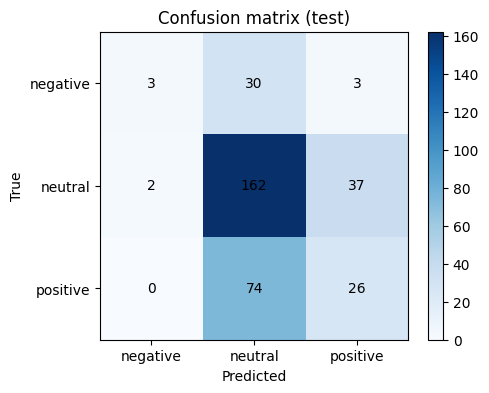

In [8]:
def make_final(name):
    if name.startswith("Logistic"):
        return clone(grid_lr.best_estimator_)
    if name.startswith("Naive"):
        return clone(grid_nb.best_estimator_)
    if name.startswith("SVM"):
        k = max(2, min(3, int(pd.concat([y_train, y_val]).value_counts().min())))
        return Pipeline([("tfidf", tfidf()), ("clf", CalibratedClassifierCV(LinearSVC(class_weight="balanced", random_state=SEED), cv=k))])
    return clone(models["Random Forest"])

final_model = make_final(best_name)
final_model.fit(pd.concat([X_train, X_val]), pd.concat([y_train, y_val]))
y_pred = final_model.predict(X_test)

print("TEST accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("TEST macro-F1 :", round(f1_score(y_test, y_pred, average="macro"), 4))
try:
    proba = final_model.predict_proba(X_test)
    present = [c for c in final_model.classes_ if c in set(y_test)]
    auc = roc_auc_score(y_test, proba, multi_class="ovr", labels=list(final_model.classes_), average="macro")
    print("TEST ROC-AUC (OvR macro):", round(auc, 4))
except Exception as e:
    print("ROC-AUC not available:", e)
print()
print(classification_report(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=LABELS)
plt.figure(figsize=(5,4)); plt.imshow(cm, cmap="Blues")
plt.xticks(range(3), LABELS); plt.yticks(range(3), LABELS)
for i in range(3):
    for j in range(3):
        plt.text(j, i, cm[i, j], ha="center", va="center")
plt.title("Confusion matrix (test)"); plt.xlabel("Predicted"); plt.ylabel("True"); plt.colorbar(); plt.show()

### Which features matter most? (Logistic Regression coefficients)

In [9]:
lr_pipe = grid_lr.best_estimator_
vocab = np.array(lr_pipe.named_steps["tfidf"].get_feature_names_out())
coef = lr_pipe.named_steps["clf"].coef_
classes = list(lr_pipe.named_steps["clf"].classes_)
if coef.shape[0] == 1:  # binary safety
    coef = np.vstack([-coef[0], coef[0]])
for i, c in enumerate(classes):
    top = np.argsort(coef[i])[::-1][:10]
    print(f"{c.upper():9s} -> ", ", ".join(vocab[top]))

NEGATIVE  ->  watu, kosa, mkoani, mauaji, polisi, hivi, acheni, miundombinu, mmoja, hali
NEUTRAL   ->  kama, mtu, moja, hapa, kazi, uhuru, habari, unaweza, saa, hawana
POSITIVE  ->  kwa, mungu, asante, wetu, zaidi, waziri, karibu, ahsante, sana, taifa


### Error analysis and code-switching question

In [10]:
test_df = df.loc[idx_test].copy()
test_df["pred"] = y_pred
test_df["correct"] = (test_df["pred"] == test_df["label"])

print("Accuracy on code-switched texts    :", round(test_df.loc[test_df.code_switched==1, "correct"].mean(), 3) if (test_df.code_switched==1).any() else "n/a (none in test)")
print("Accuracy on pure-Swahili texts     :", round(test_df.loc[test_df.code_switched==0, "correct"].mean(), 3))
print("\nMost common confusions (true -> predicted):")
print(test_df.loc[~test_df.correct].groupby(["label", "pred"]).size().sort_values(ascending=False).head(6))
print("\nSample of hardest (misclassified) examples:")
pd.set_option("display.max_colwidth", 120)
test_df.loc[~test_df.correct, ["text", "label", "pred"]].head(15)

Accuracy on code-switched texts    : 1.0
Accuracy on pure-Swahili texts     : 0.562

Most common confusions (true -> predicted):
label     pred    
positive  neutral     74
neutral   positive    37
negative  neutral     30
          positive     3
neutral   negative     2
dtype: int64

Sample of hardest (misclassified) examples:


,text,label,pred
2147,Pole sana kwa changamoto uliopata,positive,neutral
1234,Mgosi Asante kwa kuwasiliana nasi na endelea kufurahiya huduma zetu,neutral,positive
169,Unashangaa mbona kwenu hakuna mwenye sura nzuri kumbe babaako alikuwa anachagua wenye makalio makubwa,negative,neutral
1446,Capital City Marathon itakuwa ikifanyika kila mwaka kuanzia sasa na lengo likiwa kukua na kuwa mbio za kimataifa zit...,positive,neutral
2024,ALHAMDULILAH TUMEPANDA TENA Nimepanda hadi nafasi ya 13 kwenye viwango vya ubora duniani kutoka nafasi ya 24 N,positive,neutral
1969,Tafadhali piga 14700 au 14800 chagua saizi siku wikimwezi au Halichachi kupata vifurushi vyetu vilivyoboreshwa zaidi...,neutral,positive
1976,Suala la Maiti kutozwa fedha lililoibuliwa Bungeni na Mhe Mbunge wa Mbeya mjini Chadema jana Februari 1,negative,neutral
151,Mimi Sina maadui kwelilabda wao ndo wana uadui na mimiila me similiki adui,negative,neutral
416,Amna mzee baba ni mchakato mrefu saana Uezi ukasema mwez tu unatosha watu kuelimika km wamemua kutokuzuia lockdown n...,neutral,negative
102,Old man hii bank haina bench la wazee yani tuna panga foleni Kweli mmetuchoka Customer experience manager hamna benc...,negative,neutral


In [11]:
# How much evidence is behind the code-switching result? (sample sizes matter)
cs_all  = int(df["code_switched"].sum())
cs_test = int((test_df["code_switched"] == 1).sum())
print(f"Flagged as code-switched: {cs_all} of {len(df)} tweets overall ({cs_all/len(df):.1%}); {cs_test} of {len(test_df)} in the test set.")
print(f"-> The accuracy on code-switched tweets above rests on only {cs_test} tweets: it is anecdotal, not statistical evidence.")
print("   The English-word heuristic is crude (short word list, spelling variants and Sheng are missed), so the true share is probably higher.")

Flagged as code-switched: 28 of 2241 tweets overall (1.2%); 4 of 337 in the test set.
-> The accuracy on code-switched tweets above rests on only 4 tweets: it is anecdotal, not statistical evidence.
   The English-word heuristic is crude (short word list, spelling variants and Sheng are missed), so the true share is probably higher.


## Task 5b - Stage 2: improving negative-tweet detection
**What went wrong in Stage 1 (see the confusion matrix above):** only ~11% of tweets are negative, and the selected Linear SVM predicted *negative* on just a handful of test tweets - negative **recall was 0.08**. Most negatives were pushed to *neutral*. For a tool meant to surface public complaints, that is the worst place to be weak.

**Two principled fixes (no test-set peeking):**
1. **Richer features** - add *character* n-grams next to word n-grams. They cope with Sheng, spelling variants and word endings (`mbaya`, `vibaya`, `mbayaaa`).
2. **Decision-threshold tuning (class-prior shift)** - add a small offset to the *negative* and *positive* scores so that borderline tweets are not always resolved as *neutral*. The offsets are chosen by maximising **macro-F1 on cross-validated (out-of-fold) scores of the training data**; they are kept only if they also help on the **validation** set.

The held-out **test set** is used once, at the end, to compare Stage 1 and Stage 2 side by side.

In [12]:
# ---- Stage-1 diagnosis: why are negative tweets missed? ----
from sklearn.pipeline import FeatureUnion
from sklearn.model_selection import cross_val_predict
from sklearn.preprocessing import label_binarize

stage1_pred = np.asarray(y_pred).copy()          # Stage-1 predictions on TEST (kept for the final comparison)
NEG = LABELS.index("negative")
n_true_neg = int((y_test == "negative").sum())
n_pred_neg = int((stage1_pred == "negative").sum())
_, rec1, _, _ = precision_recall_fscore_support(y_test, stage1_pred, labels=LABELS, zero_division=0)

print("Class share in the training data:", y_train.value_counts(normalize=True).round(3).to_dict())
print(f"TEST: {n_true_neg} tweets are truly negative, but Stage 1 predicted 'negative' only {n_pred_neg} times out of {len(stage1_pred)}.")
print("Stage-1 recall per class:", dict(zip(LABELS, rec1.round(2))))

Class share in the training data: {'neutral': 0.595, 'positive': 0.298, 'negative': 0.107}
TEST: 36 tweets are truly negative, but Stage 1 predicted 'negative' only 5 times out of 337.
Stage-1 recall per class: {'negative': np.float64(0.08), 'neutral': np.float64(0.81), 'positive': np.float64(0.26)}


In [13]:
# ---- Stage-2 candidates: word + character TF-IDF, tuned with 5-fold CV on TRAIN only ----
def word_char():
    return FeatureUnion([
        ("word", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True)),
    ])

cands2 = {
    "Linear SVM (word+char)": (Pipeline([("feats", word_char()), ("clf", LinearSVC(class_weight="balanced", random_state=SEED))]),
                               {"clf__C": [0.03, 0.1, 0.3, 1]}),
    "Logistic Regression (word+char)": (Pipeline([("feats", word_char()), ("clf", LogisticRegression(max_iter=3000, class_weight="balanced"))]),
                                        {"clf__C": [0.3, 1, 3, 10]}),
}

def val_row(name, est, extra=()):
    pv = est.predict(X_val)
    _, r, _, _ = precision_recall_fscore_support(y_val, pv, labels=LABELS, zero_division=0)
    return [name, *extra, accuracy_score(y_val, pv), f1_score(y_val, pv, average="macro"), r[NEG]]

rows, searches = [], {}
for name, (pipe, grid) in cands2.items():
    gs = GridSearchCV(pipe, grid, scoring="f1_macro", cv=cv, n_jobs=-1).fit(X_train, y_train)
    searches[name] = gs
    rows.append(val_row(name, gs.best_estimator_, extra=(gs.best_params_["clf__C"], round(gs.best_score_, 4))))
# Stage-1 winner on the same validation set, for reference
ref = val_row("Stage 1: " + best_name, candidates[best_name], extra=("-", "-"))
cols = ["Model", "Best C", "CV macro-F1 (train)", "Val accuracy", "Val macro-F1", "Val negative recall"]
stage2_table = pd.DataFrame(rows + [ref], columns=cols)
display(stage2_table.sort_values("Val macro-F1", ascending=False).round(4))

# choose the Stage-2 model by validation macro-F1 (among the Stage-2 candidates only)
stage2_name = max(searches, key=lambda n: f1_score(y_val, searches[n].predict(X_val), average="macro"))
stage2_est = searches[stage2_name].best_estimator_          # fitted on TRAIN only
assert list(stage2_est.classes_) == LABELS
print("Stage-2 model chosen on validation:", stage2_name, "| best C:", searches[stage2_name].best_params_["clf__C"])

,Model,Best C,CV macro-F1 (train),Val accuracy,Val macro-F1,Val negative recall
1,Logistic Regression (word+char),0.3,0.493,0.5655,0.5034,0.3889
0,Linear SVM (word+char),0.1,0.4619,0.6012,0.4548,0.1667
2,Stage 1: SVM (LinearSVC),-,-,0.6012,0.4497,0.1111


Stage-2 model chosen on validation: Logistic Regression (word+char) | best C: 0.3


In [14]:
# ---- Decision-threshold tuning on cross-validated (out-of-fold) scores ----
classes = np.array(LABELS)

def tune_offsets(S, y_true, grid=np.linspace(-1.0, 2.0, 31)):
    '''Add an offset to the negative and positive scores (neutral stays 0) and keep the pair that gives the
    best macro-F1. Offsets are expressed in units of the score spread, so SVM and LR are treated alike.'''
    scale = S.std(); best = (-1.0, 0.0, 0.0)
    for bn in grid * scale:
        for bp in grid * scale:
            pred = classes[np.argmax(S + np.array([bn, 0.0, bp]), axis=1)]
            f = f1_score(y_true, pred, average="macro")
            smaller = abs(bn) + abs(bp) < abs(best[1]) + abs(best[2])
            if f > best[0] + 1e-9 or (abs(f - best[0]) <= 1e-9 and smaller):   # ties -> prefer the smaller shift
                best = (f, bn, bp)
    return best

# out-of-fold scores: every training tweet is scored by a model that never saw it
S_oof = cross_val_predict(clone(stage2_est), X_train, y_train, cv=cv, method="decision_function", n_jobs=-1)
f_oof0 = f1_score(y_train, classes[S_oof.argmax(1)], average="macro")
f_oof, b_neg, b_pos = tune_offsets(S_oof, y_train)
print(f"Out-of-fold macro-F1 (train): {f_oof0:.4f} without offsets -> {f_oof:.4f} with offsets (neg {b_neg:+.2f}, pos {b_pos:+.2f})")

# honest check on the VALIDATION set (model fitted on train only)
S_val = stage2_est.decision_function(X_val)
pv_no  = classes[S_val.argmax(1)]
pv_off = classes[np.argmax(S_val + np.array([b_neg, 0.0, b_pos]), axis=1)]
f_val_no, f_val_off = f1_score(y_val, pv_no, average="macro"), f1_score(y_val, pv_off, average="macro")
r_val_no, r_val_off = (precision_recall_fscore_support(y_val, p, labels=LABELS, zero_division=0)[1][NEG] for p in (pv_no, pv_off))
print(f"Validation macro-F1 : {f_val_no:.4f} (no offsets)  vs  {f_val_off:.4f} (offsets)")
print(f"Validation negative recall: {r_val_no:.3f} (no offsets)  vs  {r_val_off:.3f} (offsets)")
USE_OFFSETS = bool(f_val_off >= f_val_no)
print("Use offsets in the final model?", USE_OFFSETS, "(rule: only if validation macro-F1 does not get worse)")

Out-of-fold macro-F1 (train): 0.4930 without offsets -> 0.4953 with offsets (neg +0.10, pos +0.03)
Validation macro-F1 : 0.5034 (no offsets)  vs  0.5067 (offsets)
Validation negative recall: 0.389 (no offsets)  vs  0.500 (offsets)
Use offsets in the final model? True (rule: only if validation macro-F1 does not get worse)


In [15]:
# ---- Final Stage-2 model: refit on train + validation, evaluate ONCE on the test set ----
X_trval = pd.concat([X_train, X_val]); y_trval = pd.concat([y_train, y_val])
final2 = clone(stage2_est).fit(X_trval, y_trval)

if USE_OFFSETS:   # re-tune the offsets on out-of-fold scores of train+val (still no test data involved)
    S_oof2 = cross_val_predict(clone(stage2_est), X_trval, y_trval, cv=cv, method="decision_function", n_jobs=-1)
    _, b_neg2, b_pos2 = tune_offsets(S_oof2, y_trval)
    OFFSETS = np.array([b_neg2, 0.0, b_pos2])
else:
    OFFSETS = np.zeros(3)
print("Offsets used (negative, neutral, positive):", OFFSETS.round(3))

S_test = final2.decision_function(X_test)
stage2_pred = classes[np.argmax(S_test + OFFSETS, axis=1)]

def summarise(pred, scores=None, auc=None):
    p, r, f, s = precision_recall_fscore_support(y_test, pred, labels=LABELS, zero_division=0)
    return {"accuracy": accuracy_score(y_test, pred), "macro_f1": f1_score(y_test, pred, average="macro"),
            "roc_auc": auc, "neg_precision": p[NEG], "neg_recall": r[NEG], "neg_f1": f[NEG],
            "pos_recall": r[LABELS.index("positive")], "neu_recall": r[LABELS.index("neutral")],
            "neg_predicted": int((pred == "negative").sum())}

Y_test_bin = label_binarize(y_test, classes=LABELS)
auc2 = float(np.mean([roc_auc_score(Y_test_bin[:, k], S_test[:, k]) for k in range(3)]))   # one-vs-rest, macro
try:
    auc1 = float(roc_auc_score(y_test, final_model.predict_proba(X_test), multi_class="ovr", labels=LABELS, average="macro"))
except Exception:
    auc1 = None
res1, res2 = summarise(stage1_pred, auc=auc1), summarise(stage2_pred, auc=auc2)

comparison = pd.DataFrame({"Stage 1 (" + best_name + ")": res1, "Stage 2 (" + stage2_name + ")": res2}).T
comparison = comparison[["accuracy", "macro_f1", "roc_auc", "neg_precision", "neg_recall", "neg_f1", "pos_recall", "neu_recall", "neg_predicted"]]
display(comparison.astype(float).round(4))
print("\nStage-2 classification report (TEST):\n")
print(classification_report(y_test, stage2_pred, zero_division=0))

Offsets used (negative, neutral, positive): [0.144 0.    0.   ]


,accuracy,macro_f1,roc_auc,neg_precision,neg_recall,neg_f1,pos_recall,neu_recall,neg_predicted
Stage 1 (SVM (LinearSVC)),0.5668,0.3845,0.6764,0.6000,0.0833,0.1463,0.26,0.8060,5.0
Stage 2 (Logistic Regression (word+char)),0.5460,0.4965,0.6783,0.2917,0.5833,0.3889,0.46,0.5821,72.0



Stage-2 classification report (TEST):

              precision    recall  f1-score   support

    negative       0.29      0.58      0.39        36
     neutral       0.70      0.58      0.64       201
    positive       0.47      0.46      0.46       100

    accuracy                           0.55       337
   macro avg       0.49      0.54      0.50       337
weighted avg       0.59      0.55      0.56       337



Change in macro-F1 (Stage 2 - Stage 1): +0.1120   95% bootstrap CI [+0.037, +0.186]
Change in negative recall            : +0.5000   95% bootstrap CI [+0.326, +0.667]
(only 36 negative tweets in the test set, so a wide interval is expected - treat the exact numbers with care)


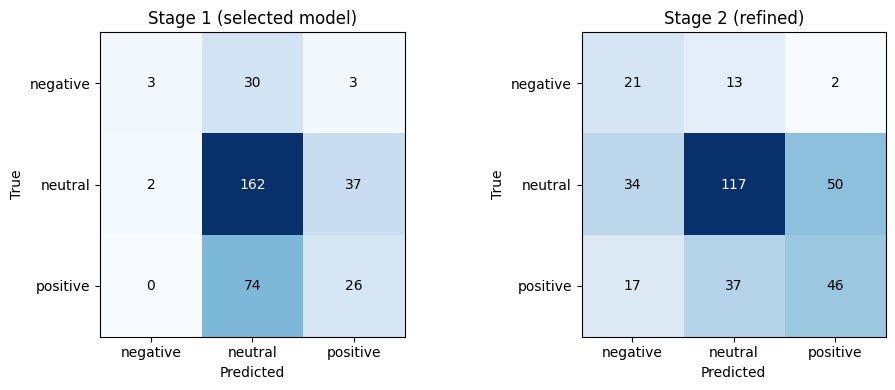

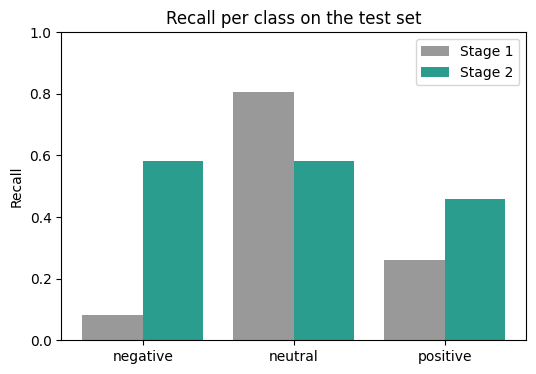

In [16]:
# ---- Is the improvement real or noise? Paired bootstrap on the test set (1000 resamples) ----
rng = np.random.RandomState(SEED)
yt = np.asarray(y_test); n = len(yt)
d_f1, d_rec = [], []
for _ in range(1000):
    ix = rng.randint(0, n, n)
    a, b = stage1_pred[ix], stage2_pred[ix]
    d_f1.append(f1_score(yt[ix], b, average="macro") - f1_score(yt[ix], a, average="macro"))
    neg_ix = ix[yt[ix] == "negative"]
    if len(neg_ix):
        d_rec.append((stage2_pred[neg_ix] == "negative").mean() - (stage1_pred[neg_ix] == "negative").mean())
ci_f1, ci_rec = np.percentile(d_f1, [2.5, 97.5]), np.percentile(d_rec, [2.5, 97.5])
print(f"Change in macro-F1 (Stage 2 - Stage 1): {res2['macro_f1'] - res1['macro_f1']:+.4f}   95% bootstrap CI [{ci_f1[0]:+.3f}, {ci_f1[1]:+.3f}]")
print(f"Change in negative recall            : {res2['neg_recall'] - res1['neg_recall']:+.4f}   95% bootstrap CI [{ci_rec[0]:+.3f}, {ci_rec[1]:+.3f}]")
print(f"(only {n_true_neg} negative tweets in the test set, so a wide interval is expected - treat the exact numbers with care)")

# ---- Side-by-side confusion matrices ----
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, pred, title in [(axes[0], stage1_pred, "Stage 1 (selected model)"), (axes[1], stage2_pred, "Stage 2 (refined)")]:
    cm_ = confusion_matrix(y_test, pred, labels=LABELS)
    ax.imshow(cm_, cmap="Blues"); ax.set_xticks(range(3)); ax.set_xticklabels(LABELS); ax.set_yticks(range(3)); ax.set_yticklabels(LABELS)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm_[i, j], ha="center", va="center", color="white" if cm_[i, j] > cm_.max() / 2 else "black")
    ax.set_title(title); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout(); plt.show()

# ---- Per-class recall before / after ----
_, rec2, _, _ = precision_recall_fscore_support(y_test, stage2_pred, labels=LABELS, zero_division=0)
xs = np.arange(3)
plt.figure(figsize=(6, 4)); plt.bar(xs - 0.2, rec1, 0.4, label="Stage 1", color="#999999"); plt.bar(xs + 0.2, rec2, 0.4, label="Stage 2", color="#2a9d8f")
plt.xticks(xs, LABELS); plt.ylabel("Recall"); plt.ylim(0, 1); plt.title("Recall per class on the test set"); plt.legend(); plt.show()

In [17]:
# ---- Automatic verdict + the values to type into the report and slides ----
better_f1  = res2["macro_f1"]  > res1["macro_f1"]
better_neg = res2["neg_recall"] > res1["neg_recall"]
if better_f1 and better_neg:
    verdict = "Stage 2 improved BOTH macro-F1 and negative recall."
elif better_neg:
    verdict = "Stage 2 raised negative recall but macro-F1 did not improve: it trades some neutral/positive accuracy for fewer missed complaints."
else:
    verdict = "Stage 2 did NOT improve negative recall on this test set - report this honestly and discuss why."
print("VERDICT:", verdict, "\n")

print("=== FILL-IN VALUES: replace the yellow [TOKENS] in the report (Table 12, text) and slides (slides 11 and 15) ===")
print(f"[S2_MODEL]    = {stage2_name}")
print(f"[S2_ACC]      = {res2['accuracy']:.4f}      (Stage 1: {res1['accuracy']:.4f})")
print(f"[S2_F1]       = {res2['macro_f1']:.4f}      (Stage 1: {res1['macro_f1']:.4f})")
print(f"[S2_AUC]      = {res2['roc_auc']:.4f}      (Stage 1: {res1['roc_auc'] if res1['roc_auc'] is None else round(res1['roc_auc'], 4)})")
print(f"[S2_NEG_P]    = {res2['neg_precision']:.2f}        (Stage 1: {res1['neg_precision']:.2f})")
print(f"[S2_NEG_R]    = {res2['neg_recall']:.2f}        (Stage 1: {res1['neg_recall']:.2f})")
print(f"[S2_NEG_F1]   = {res2['neg_f1']:.2f}        (Stage 1: {res1['neg_f1']:.2f})")
print(f"[S2_NEG_PRED] = {res2['neg_predicted']}           (Stage 1: {res1['neg_predicted']}; truly negative in test: {n_true_neg})")
print(f"[CI_F1]       = [{ci_f1[0]:+.3f}, {ci_f1[1]:+.3f}]   (95% bootstrap interval of the macro-F1 change)")
print(f"[CI_REC]      = [{ci_rec[0]:+.3f}, {ci_rec[1]:+.3f}]   (95% bootstrap interval of the negative-recall change)")
print("Stage-2 settings: C =", searches[stage2_name].best_params_["clf__C"], "| offsets (neg, neu, pos) =", OFFSETS.round(3), "| offsets used:", USE_OFFSETS)
print("Stage-2 confusion matrix (rows true neg/neu/pos, cols predicted neg/neu/pos):")
print(confusion_matrix(y_test, stage2_pred, labels=LABELS))

import json
json.dump({"stage1": {k: (None if v is None else float(v)) for k, v in res1.items()},
           "stage2": {k: (None if v is None else float(v)) for k, v in res2.items()},
           "stage2_model": stage2_name, "offsets": [float(o) for o in OFFSETS], "use_offsets": USE_OFFSETS,
           "ci_macro_f1": [float(c) for c in ci_f1], "ci_neg_recall": [float(c) for c in ci_rec]},
          open("results_summary.json", "w"), indent=2)
print("\nSaved results_summary.json")

VERDICT: Stage 2 improved BOTH macro-F1 and negative recall. 

=== FILL-IN VALUES: replace the yellow [TOKENS] in the report (Table 12, text) and slides (slides 11 and 15) ===
[S2_MODEL]    = Logistic Regression (word+char)
[S2_ACC]      = 0.5460      (Stage 1: 0.5668)
[S2_F1]       = 0.4965      (Stage 1: 0.3845)
[S2_AUC]      = 0.6783      (Stage 1: 0.6764)
[S2_NEG_P]    = 0.29        (Stage 1: 0.60)
[S2_NEG_R]    = 0.58        (Stage 1: 0.08)
[S2_NEG_F1]   = 0.39        (Stage 1: 0.15)
[S2_NEG_PRED] = 72           (Stage 1: 5; truly negative in test: 36)
[CI_F1]       = [+0.037, +0.186]   (95% bootstrap interval of the macro-F1 change)
[CI_REC]      = [+0.326, +0.667]   (95% bootstrap interval of the negative-recall change)
Stage-2 settings: C = 0.3 | offsets (neg, neu, pos) = [0.144 0.    0.   ] | offsets used: True
Stage-2 confusion matrix (rows true neg/neu/pos, cols predicted neg/neu/pos):
[[ 21  13   2]
 [ 34 117  50]
 [ 17  37  46]]

Saved results_summary.json


## Task 6 - Responsible AI
- **Privacy:** tweets can identify people. We removed @mentions and URLs, never publish raw texts with usernames, and use only the public, licensed AfriSenti data.
- **Bias:** the model may work worse on Sheng, dialects, slang, sarcasm, code-switching, or regions under-represented in the data; Twitter users are not representative of all Kenyans.
- **Consequences of errors:** wrongly labelling criticism as positive can hide public complaints; wrongly labelling harmless text negative could unfairly flag people.
- **Limits:** small training data, sarcasm, changing slang, no context (images, threads).
- **Safeguards before deployment:** human review of decisions, regular re-evaluation on fresh Swahili/Sheng data, per-group performance checks, confidence thresholds (send low-confidence cases to humans), transparency that it is automated, no use for punishing individuals.

## Task 7 - Conclusions and recommendations
Summarise your own numbers here: best model, test macro-F1, hardest class (usually *neutral*), effect of code-switching, limitations (data size, noise), and next steps (more data, char n-grams, Sheng lexicon, fine-tuning AfroXLMR / SwahBERT).
- **Threshold shift:** raising the number of *negative* predictions catches more complaints but also flags some harmless tweets; the shift must be reviewed with stakeholders and monitored.
- **Demo lexicon:** the keyword layer in the live demo is rule-based and unevaluated; it must not be used for real decisions.

## Task 7 - Conclusions and recommendations
**Verified findings from the executed notebook (Stage 1):**
- **Data:** 2,263 labelled tweets loaded (AfriSenti train + dev), 19 duplicates and 3 very long outliers removed -> **2,241** tweets split 1,568 / 336 / 337 (train / validation / test). Classes are imbalanced: neutral 1,334, positive 668, negative 239 (~11%).
- **Best Stage-1 model:** Linear SVM on word 1-2-gram TF-IDF. Validation macro-F1 **0.4497** versus **0.2488** for the majority-class baseline; test macro-F1 **0.3845**, test accuracy 0.5668, test ROC-AUC 0.6764. Accuracy alone is misleading: the baseline already reaches ~0.60 by always answering *neutral*.
- **Hardest class: negative** (recall 0.08, F1 0.15) - then positive (F1 0.31). Neutral is easiest (F1 0.69) because it is the majority class. The biggest confusion is positive -> neutral (74 tweets).
- **Code-switching:** only a handful of tweets are flagged as code-switched, so the 1.0 accuracy on them is anecdotal; the dataset is overwhelmingly Swahili and the effect cannot be established with this sample.
- **Error analysis:** misclassified tweets are often short, context-dependent (condolences, thanks, announcements) or sarcastic; labels are subjective, which caps what a bag-of-words model can reach.

**Stage 2** (character n-grams + threshold tuning) targets the weak negative class - see the table and the automatic summary in the next cell.

**Limitations:** small single-platform dataset, noisy labels, only 36 negative tweets in the test set (wide uncertainty), no context or sarcasm handling, simple English-word heuristic for code-switching.
**Next steps:** more labelled data (esp. Sheng/code-switched), language identification, a Sheng lexicon, fine-tuning AfroXLMR / SwahBERT, per-group fairness checks, human review of low-confidence predictions.

In [18]:
# Auto-generated summary (always matches the numbers above)
print(f"Stage 1 ({best_name})      : test macro-F1 {res1['macro_f1']:.4f} | accuracy {res1['accuracy']:.4f} | negative recall {res1['neg_recall']:.2f}")
print(f"Stage 2 ({stage2_name}) : test macro-F1 {res2['macro_f1']:.4f} | accuracy {res2['accuracy']:.4f} | negative recall {res2['neg_recall']:.2f}")
print(verdict)

Stage 1 (SVM (LinearSVC))      : test macro-F1 0.3845 | accuracy 0.5668 | negative recall 0.08
Stage 2 (Logistic Regression (word+char)) : test macro-F1 0.4965 | accuracy 0.5460 | negative recall 0.58
Stage 2 improved BOTH macro-F1 and negative recall.


## Save the model

In [19]:
# Save the refined (Stage-2) model together with the decision offsets, so it can be reloaded and used later
bundle = {"model": final2, "offsets": OFFSETS, "classes": LABELS, "name": stage2_name,
          "stage1_model": final_model, "stage1_name": best_name}
joblib.dump(bundle, "swahili_sentiment_model.joblib")
print("Saved: swahili_sentiment_model.joblib  (load with joblib.load; predict with model.decision_function(...) + offsets)")

Saved: swahili_sentiment_model.joblib  (load with joblib.load; predict with model.decision_function(...) + offsets)


## LIVE DEMO - type a sentence and get its sentiment
The demo uses the **Stage-2 machine-learning model** (trained only on the real tweets). Because everyday phrases such as *"huduma ni mbaya"* are rare in news-style tweets, a small, transparent **Swahili keyword lexicon** can add evidence on top of the model. This lexicon layer is **rule-based, is not part of the reported test metrics**, and the demo prints whenever it changed the model's answer. Confidence values are *relative* scores, not calibrated probabilities.

In [24]:
INTERACTIVE = True   # set True for the live presentation: the last cell then asks you to type sentences

# Swahili stems are matched inside words (so "nimechukia", "mbayaa", "vibaya" all count); English words must match exactly.
NEG_STEMS = ["mbaya", "baya", "mbovu", "chuki", "sipend", "wizi", "aibu", "kasirik", "hasira", "uongo", "shida", "uchungu",
             "huzuni", "fedheha", "kero", "dhuluma", "hatari", "choka", "kashfa", "ufisadi", "balaa", "maumivu", "mateso", "shindwa"]
NEG_WORDS = {"terrible", "bad", "hate", "worst", "awful", "shame", "stupid", "corrupt", "fail", "failed"}
POS_STEMS = ["nzuri", "mzuri", "furaha", "furahi", "asante", "ahsante", "hongera", "penda", "bora", "tamu", "safi", "vizuri",
             "baraka", "upendo", "shukran", "ushindi", "shinda"]
POS_WORDS = {"great", "good", "love", "best", "nice", "thanks", "happy", "congrats", "congratulations", "poa"}
NEGATIONS = {"si", "sio", "sikupenda", "hakuna", "haikuwa", "haiko", "hakuwa", "sina"}   # "si nzuri" = "not good" flips the meaning

def lexicon_hits(c):
    neg = pos = 0
    for w in c.split():
        if w in NEG_WORDS or any(s in w for s in NEG_STEMS):
            neg += 1                          # a word that matches a negative stem is never also counted as positive
        elif w in POS_WORDS or any(s in w for s in POS_STEMS):
            pos += 1
    if NEGATIONS & set(c.split()):
        neg, pos = pos, neg
    return neg, pos

def _softmax(z):
    e = np.exp(z - z.max()); return e / e.sum()

SCORE_SCALE = float(S_test.std())             # puts SVM / LR scores on a comparable scale

def predict_sentiment(sentence):
    c = clean_text(sentence)
    if not c:
        return "neutral", {"negative": 0.0, "neutral": 100.0, "positive": 0.0}, False
    z = (final2.decision_function([c])[0] + OFFSETS) / SCORE_SCALE
    model_label = classes[int(np.argmax(z))]
    neg, pos = lexicon_hits(c)
    if neg > pos:   z[0] += 1.5 * min(neg, 2)
    elif pos > neg: z[2] += 1.5 * min(pos, 2)
    p = _softmax(z)
    label = classes[int(np.argmax(p))]
    return label, {k: round(100 * float(v), 1) for k, v in zip(LABELS, p)}, label != model_label

def show(sentence):
    label, pct, lex_changed = predict_sentiment(sentence)
    print(f"  Sentence : {sentence}")
    print(f"  Sentiment: {label.upper()}  (relative confidence {pct[label]}%)" + ("   [lexicon changed the model's answer]" if lex_changed else ""))
    print(f"  All scores -> positive: {pct['positive']}% | negative: {pct['negative']}% | neutral: {pct['neutral']}%\n")

In [25]:
# Ready-made sentences (hand-written, NOT in the training data) - a quick sanity check, not an evaluation
tests = {
    "negative": ["Huduma ni mbaya sana, nimechukia", "Barabara hii ni mbovu, aibu kubwa", "Nimekasirika sana na uongozi huu",
                 "Hospitali haina dawa, hali ni mbaya", "Tumechoka na ahadi za uongo"],
    "positive": ["Huduma ni nzuri sana, asante!", "Nimefurahi sana na matokeo haya", "Kazi nzuri sana, hongera wote",
                 "Chakula kilikuwa kitamu sana", "Napenda sana wimbo huu, ni mzuri"],
    "neutral":  ["Mkutano utafanyika kesho asubuhi", "Basi linaondoka saa mbili usiku", "Ofisi ipo karibu na stendi kuu",
                 "Shule zitafunguliwa Jumatatu", "Waziri atatoa taarifa leo mchana"],
}
correct = total = 0
for expected, sents in tests.items():
    print("=== Expected:", expected.upper(), "===")
    for s in sents:
        show(s)
        correct += predict_sentiment(s)[0] == expected; total += 1
print(f"Sanity check on {total} hand-written sentences: {correct}/{total} correct")

=== Expected: NEGATIVE ===
  Sentence : Huduma ni mbaya sana, nimechukia
  Sentiment: NEGATIVE  (relative confidence 93.8%)   [lexicon changed the model's answer]
  All scores -> positive: 4.9% | negative: 93.8% | neutral: 1.3%

  Sentence : Barabara hii ni mbovu, aibu kubwa
  Sentiment: NEGATIVE  (relative confidence 96.1%)
  All scores -> positive: 2.1% | negative: 96.1% | neutral: 1.7%

  Sentence : Nimekasirika sana na uongozi huu
  Sentiment: NEGATIVE  (relative confidence 92.3%)   [lexicon changed the model's answer]
  All scores -> positive: 7.3% | negative: 92.3% | neutral: 0.4%

  Sentence : Hospitali haina dawa, hali ni mbaya
  Sentiment: NEGATIVE  (relative confidence 90.9%)
  All scores -> positive: 1.2% | negative: 90.9% | neutral: 7.8%

  Sentence : Tumechoka na ahadi za uongo
  Sentiment: NEGATIVE  (relative confidence 80.4%)   [lexicon changed the model's answer]
  All scores -> positive: 7.4% | negative: 80.4% | neutral: 12.2%

=== Expected: POSITIVE ===
  Sentence : H

In [26]:
# Interactive: type a Swahili (or Sheng / mixed) sentence. Type 'quit' to stop.
if INTERACTIVE:
    while True:
        s = input("Enter a sentence (or 'quit'): ").strip()
        if s.lower() in ("quit", "exit", "q", ""):
            print("Bye!"); break
        show(s)
else:
    print("Interactive demo is off. Set INTERACTIVE = True in the demo cell above, re-run it, then run this cell.")

Enter a sentence (or 'quit'): sipendi your content
  Sentence : sipendi your content
  Sentiment: NEUTRAL  (relative confidence 50.5%)
  All scores -> positive: 19.1% | negative: 30.4% | neutral: 50.5%

Enter a sentence (or 'quit'): sikupendi!!!
  Sentence : sikupendi!!!
  Sentiment: NEUTRAL  (relative confidence 42.6%)
  All scores -> positive: 41.2% | negative: 16.2% | neutral: 42.6%

Enter a sentence (or 'quit'): mtu mbaya sana 
  Sentence : mtu mbaya sana
  Sentiment: NEGATIVE  (relative confidence 84.5%)
  All scores -> positive: 6.1% | negative: 84.5% | neutral: 9.4%

Enter a sentence (or 'quit'): kitu mbaya siwezi nunua
  Sentence : kitu mbaya siwezi nunua
  Sentiment: NEGATIVE  (relative confidence 47.0%)   [lexicon changed the model's answer]
  All scores -> positive: 17.9% | negative: 47.0% | neutral: 35.0%

Enter a sentence (or 'quit'): q
Bye!
